In [1]:
from pathlib import Path
from itertools import permutations, product
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm, friedmanchisquare, ttest_1samp, rankdata
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300})


In [4]:
INPUT_MODE = 'clean'
CLEAN_FILE = Path('/content/all_probe_rows_clean.csv')
RAW_FOLDER = Path('raw_data')
OUTPUT_FOLDER = Path('results')
OUTPUT_FOLDER.mkdir(exist_ok=True, parents=True)

SET_SIZES = [4, 6, 8, 10]
N_BOOTSTRAP = 5000
SEED = 20261031
rng = np.random.default_rng(SEED)

In [5]:
def clean_key(column):
    # Keep actual missing values missing; remove brackets and quotation marks.
    text = column.astype('string').str.lower().str.strip()
    text = text.str.replace(r"[\[\]'\" ]", '', regex=True)
    return text.replace({'': pd.NA, 'none': pd.NA, 'nan': pd.NA})

def find_column(table, choices):
    for name in choices:
        if name in table.columns:
            return name
    raise ValueError('Required column not found. Expected one of: ' + str(choices))

if INPUT_MODE == 'clean':
    all_probes = pd.read_csv(CLEAN_FILE)
elif INPUT_MODE == 'raw':
    files = sorted(RAW_FOLDER.glob('*.csv'))
    if not files:
        raise FileNotFoundError('No participant CSVs found in raw_data.')
    parts = []
    for number, file in enumerate(files, start=1):
        raw = pd.read_csv(file)
        probe = raw.loc[raw['probe_number'].notna()].copy()
        rename = {
            find_column(raw, ['probeResp.keys', 'probeLoop.probeResp.keys']): 'response',
            find_column(raw, ['probeResp.rt', 'probeLoop.probeResp.rt']): 'response_rt',
            find_column(raw, ['key_resp_4.keys', 'probeLoop.key_resp_4.keys',
                              'confidenceResp.keys']): 'confidence',
            find_column(raw, ['key_resp_4.rt', 'probeLoop.key_resp_4.rt',
                              'confidenceResp.rt']): 'confidence_rt'
        }
        probe = probe.rename(columns=rename)
        keep = ['is_practice', 'block', 'trial_in_block', 'global_trial',
                'trial_id', 'set_size', 'probe_number', 'probe_word',
                'probe_status', 'correct_key', 'response', 'response_rt',
                'confidence', 'confidence_rt']
        probe = probe.reindex(columns=keep)
        probe['participant'] = f'p{number}'
        probe['source_file'] = f'input_{number}.csv'
        parts.append(probe)
    all_probes = pd.concat(parts, ignore_index=True)
else:
    raise ValueError("INPUT_MODE must be 'clean' or 'raw'.")

# Retain only documented analysis fields, even if the input has extra columns.
keep = ['participant', 'source_file', 'is_practice', 'block', 'trial_in_block',
        'global_trial', 'trial_id', 'set_size', 'probe_number', 'probe_word',
        'probe_status', 'correct_key', 'response', 'response_rt',
        'confidence', 'confidence_rt']
all_probes = all_probes.reindex(columns=keep).copy()
all_probes['response'] = clean_key(all_probes['response'])
all_probes['correct_key'] = clean_key(all_probes['correct_key'])
all_probes['probe_status'] = all_probes['probe_status'].astype('string').str.lower().str.strip()
all_probes['confidence'] = pd.to_numeric(clean_key(all_probes['confidence']), errors='coerce')
for column in ['is_practice', 'set_size', 'probe_number', 'response_rt', 'confidence_rt']:
    all_probes[column] = pd.to_numeric(all_probes[column], errors='coerce')

# Keep anonymous labels in first-appearance order.
labels = all_probes['participant'].drop_duplicates().tolist()
anonymous = {label: f'p{i+1}' for i, label in enumerate(labels)}
all_probes['participant'] = all_probes['participant'].map(anonymous)
sources = all_probes['source_file'].drop_duplicates().tolist()
all_probes['source_file'] = all_probes['source_file'].map(
    {name: f'input_{i+1}.csv' for i, name in enumerate(sources)})
print('Probe rows loaded:', len(all_probes))
display(all_probes.head())

Probe rows loaded: 1536


,participant,source_file,is_practice,block,trial_in_block,global_trial,trial_id,set_size,probe_number,probe_word,probe_status,correct_key,response,response_rt,confidence,confidence_rt
0,p1,input_1.csv,1.0,0.0,1.0,0.0,p001_P01,4.0,1.0,print,new,j,j,0.767540,<NA>,NaN
1,p1,input_1.csv,1.0,0.0,1.0,0.0,p001_P01,4.0,2.0,stones,old,f,<NA>,NaN,<NA>,NaN
2,p1,input_1.csv,1.0,0.0,1.0,0.0,p001_P01,4.0,3.0,locker,old,f,f,1.952543,3.0,1.345249
3,p1,input_1.csv,1.0,0.0,1.0,0.0,p001_P01,4.0,4.0,orders,new,j,j,1.251433,2.0,1.248190
4,p1,input_1.csv,1.0,0.0,1.0,0.0,p001_P01,4.0,5.0,title,new,j,j,0.958311,3.0,0.759070


In [6]:
# excluding the Practive things
assert all_probes['participant'].notna().all(), 'Missing participant ID.'
assert all_probes['trial_id'].notna().all(), 'Missing trial ID.'
assert all_probes['is_practice'].isin([0, 1]).all(), 'Invalid practice flag.'
assert all_probes['set_size'].isin(SET_SIZES).all(), 'Unexpected set size.'
assert all_probes['probe_number'].isin(range(1, 7)).all(), 'Unexpected probe number.'
assert all_probes['probe_status'].isin(['old', 'new']).all(), 'Unexpected probe status.'
assert not all_probes.duplicated(['participant', 'trial_id', 'probe_number']).any(), 'Duplicate probe rows.'
assert all_probes['response'].dropna().isin(['f', 'j']).all(), 'Unexpected response key.'
assert all_probes['confidence'].dropna().isin([1, 2, 3]).all(), 'Unexpected confidence.'
expected_key = all_probes['probe_status'].map({'old': 'f', 'new': 'j'})
assert all_probes['correct_key'].eq(expected_key).fillna(False).all(), 'Response mapping mismatch.'

main = all_probes.loc[all_probes['is_practice'] == 0].copy()
main['set_size'] = main['set_size'].astype(int)
main['probe_number'] = main['probe_number'].astype(int)
main['correct'] = np.nan
answered = main['response'].isin(['f', 'j'])
main.loc[answered, 'correct'] = (main.loc[answered, 'response'] ==
                                main.loc[answered, 'correct_key']).astype(float)

audit_rows = []
for participant, group in main.groupby('participant'):
    practice_count = ((all_probes['participant'] == participant) &
                      (all_probes['is_practice'] == 1)).sum()
    audit_rows.append({
        'participant': participant, 'practice_probe_rows': practice_count,
        'main_trials': group['trial_id'].nunique(), 'main_probe_rows': len(group),
        'missing_recognition_responses': group['response'].isna().sum(),
        'missing_confidence_responses': group['confidence'].isna().sum()})
audit = pd.DataFrame(audit_rows)
display(audit)
display(main.groupby(['participant', 'set_size']).agg(
    trials=('trial_id', 'nunique'), scheduled_probes=('probe_number', 'size')))
print('Valid recognition decisions:', main['response'].notna().sum())
print('Practice probes excluded:', (all_probes['is_practice'] == 1).sum())


,participant,practice_probe_rows,main_trials,main_probe_rows,missing_recognition_responses,missing_confidence_responses
0,p1,24,60,360,2,1
1,p2,24,60,360,0,0
2,p3,24,60,360,0,0
3,p4,24,60,360,0,0


trials  scheduled_probes
participant set_size                          
p1          4             15                90
            6             15                90
            8             15                90
            10            15                90
p2          4             15                90
            6             15                90
            8             15                90
            10            15                90
p3          4             15                90
            6             15                90
            8             15                90
            10            15                90
p4          4             15                90
            6             15                90
            8             15                90
            10            15                90

Valid recognition decisions: 1438
Practice probes excluded: 96


## 5. Classify responses and order confidence

| Probe | F: Seen | J: Not seen |
|---|---|---|
| Old | Hit | Miss |
| New | False alarm | Correct rejection |

For ROC analysis, scores run from **1 = high-confidence new** to **6 = high-confidence old**.
New-high, new-medium, new-low, old-low, old-medium, old-high are scores 1–6.
All outcomes are recalculated; saved outcome columns are not trusted blindly.

In [7]:
main['outcome'] = 'missing'
main.loc[(main['probe_status'] == 'old') & (main['response'] == 'f'), 'outcome'] = 'hit'
main.loc[(main['probe_status'] == 'old') & (main['response'] == 'j'), 'outcome'] = 'miss'
main.loc[(main['probe_status'] == 'new') & (main['response'] == 'f'), 'outcome'] = 'false_alarm'
main.loc[(main['probe_status'] == 'new') & (main['response'] == 'j'), 'outcome'] = 'correct_rejection'

main['evidence_score'] = np.nan
new_answer = main['response'] == 'j'
old_answer = main['response'] == 'f'
main.loc[new_answer, 'evidence_score'] = 4 - main.loc[new_answer, 'confidence']
main.loc[old_answer, 'evidence_score'] = 3 + main.loc[old_answer, 'confidence']
valid = main.loc[main['outcome'] != 'missing'].copy()
display(main['outcome'].value_counts())

,count
outcome,
hit,639
correct_rejection,633
false_alarm,86
miss,80
missing,2


## 6. Calculate SDT measures for each participant and set size
The log-linear correction is applied to **every** condition:

$$\widetilde H=\frac{h+0.5}{h+m+1},\qquad
\widetilde F=\frac{f+0.5}{f+r+1}.$$

Here h=hits, m=misses, f=false alarms and r=correct rejections.
`norm.ppf` is the inverse standard normal CDF, written z below.

$$d'=z(\widetilde H)-z(\widetilde F),\quad
c=-z(\widetilde F),\quad b=-\frac{z(\widetilde H)+z(\widetilde F)}2.$$

We follow the **assignment notation**: c is the criterion measured from the new-word
distribution; b is centred bias (often called c elsewhere). Positive b means conservative,
negative b means liberal. Model-predicted AUC is $\Phi(d'/\sqrt{2})$ under equal variance.
The one short function avoids repeating the same formulas in each resample.

In [8]:
METRICS = ['hit_rate', 'false_alarm_rate', 'dprime',
           'criterion_c', 'bias_b', 'theoretical_auc']
OUTCOMES = ['hit', 'miss', 'false_alarm', 'correct_rejection']

def calculate_sdt(counts):
    # counts can be one row or many rows; the last axis holds h, m, f, r.
    counts = np.asarray(counts, dtype=float)
    h, m, f, r = np.moveaxis(counts, -1, 0)
    hit_rate = (h + 0.5) / (h + m + 1)
    false_alarm_rate = (f + 0.5) / (f + r + 1)
    z_hit = norm.ppf(hit_rate)
    z_fa = norm.ppf(false_alarm_rate)
    dprime = z_hit - z_fa
    values = [hit_rate, false_alarm_rate, dprime, -z_fa,
              -(z_hit + z_fa) / 2, norm.cdf(dprime / np.sqrt(2))]
    return dict(zip(METRICS, values))

rows = []
for (participant, size), group in valid.groupby(['participant', 'set_size']):
    counts = group['outcome'].value_counts().reindex(OUTCOMES, fill_value=0)
    assert counts['hit'] + counts['miss'] > 0
    assert counts['false_alarm'] + counts['correct_rejection'] > 0
    values = calculate_sdt(counts.to_numpy())
    row = {'participant': participant, 'set_size': size,
           'hits': counts['hit'], 'misses': counts['miss'],
           'false_alarms': counts['false_alarm'],
           'correct_rejections': counts['correct_rejection'],
           'n_valid': len(group), 'accuracy': group['correct'].mean(),
           'median_response_rt': group['response_rt'].median(),
           'mean_confidence': group['confidence'].mean()}
    row.update(values)
    rows.append(row)
metrics = pd.DataFrame(rows)
display(metrics[['participant', 'set_size', 'hits', 'misses', 'false_alarms',
                 'correct_rejections', 'dprime', 'criterion_c', 'bias_b']])

,participant,set_size,hits,misses,false_alarms,correct_rejections,dprime,criterion_c,bias_b
0,p1,4,44,0,3,41,3.706727,1.420179,-0.433184
1,p1,6,38,7,11,34,1.656516,0.674490,-0.153768
2,p1,8,36,9,7,38,1.800576,0.982026,0.081738
3,p1,10,38,7,9,36,1.800576,0.818550,-0.081738
4,p2,4,45,0,1,44,4.138660,1.843765,-0.225565
5,p2,6,40,5,8,37,2.074451,0.897288,-0.139937
6,p2,8,41,4,8,37,2.191326,0.897288,-0.198375
7,p2,10,41,4,7,38,2.276065,0.982026,-0.156006
8,p3,4,43,2,2,43,3.208167,1.604083,-0.000000
9,p3,6,39,6,7,38,2.056504,0.982026,-0.046226


## 7. Bootstrap complete study trials
The six probes following one list are related. We therefore sample **trials**, not
individual probes. Each selected trial contributes all its available responses.
Missing decisions remain missing. Trial counts below include every scheduled trial,
even a trial with no valid decisions.

Within each participant and set size we sample the original number of trials with
replacement, 5,000 times. The 2.5th and 97.5th percentiles give a 95% interval.
Index arrays perform the repetitive sampling efficiently; they do not change the
resampling unit. If a resample has no valid old or no valid new decisions, its SDT
estimate is undefined and excluded from the interval.

In [9]:
trial_keys = ['participant', 'set_size', 'trial_id']
trial_counts = main[trial_keys].drop_duplicates().set_index(trial_keys)
observed_counts = pd.crosstab(
    [valid['participant'], valid['set_size'], valid['trial_id']], valid['outcome'])
trial_counts = trial_counts.join(observed_counts).reindex(columns=OUTCOMES).fillna(0).reset_index()

bootstrap = {}
ci_rows = []
for (participant, size), group in trial_counts.groupby(['participant', 'set_size']):
    matrix = group[OUTCOMES].to_numpy(dtype=float)
    n_trials = len(matrix)
    # Each row of indices represents one simulated experiment.
    indices = rng.integers(0, n_trials, size=(N_BOOTSTRAP, n_trials))
    resampled_counts = matrix[indices].sum(axis=1)
    estimates = calculate_sdt(resampled_counts)
    usable = ((resampled_counts[:, 0] + resampled_counts[:, 1] > 0) &
              (resampled_counts[:, 2] + resampled_counts[:, 3] > 0))
    row = {'participant': participant, 'set_size': size}
    for name in METRICS:
        estimates[name][~usable] = np.nan
        low, high = np.nanpercentile(estimates[name], [2.5, 97.5])
        row[name + '_ci_low'] = low
        row[name + '_ci_high'] = high
    bootstrap[(participant, size)] = estimates
    ci_rows.append(row)
metrics = metrics.merge(pd.DataFrame(ci_rows), on=['participant', 'set_size'])
display(metrics[['participant', 'set_size', 'dprime', 'dprime_ci_low', 'dprime_ci_high']])

,participant,set_size,dprime,dprime_ci_low,dprime_ci_high
0,p1,4,3.706727,3.319262,4.572884
1,p1,6,1.656516,1.227932,2.274842
2,p1,8,1.800576,1.013582,2.862543
3,p1,10,1.800576,1.186889,2.609058
4,p2,4,4.138660,3.723219,4.589790
5,p2,6,2.074451,1.402794,3.013136
6,p2,8,2.191326,1.734708,2.900173
7,p2,10,2.276065,1.822901,3.008333
8,p3,4,3.208167,2.471201,4.587964
9,p3,6,2.056504,1.560694,2.784727


## Group means and hierarchical confidence intervals
Group point estimates are the **mean of participant estimates**, not SDT calculated
from pooled responses. To include between-participant variation, each group bootstrap
draw first samples participants with replacement. For each sampled participant, it
then draws one whole-trial bootstrap estimate from Section 7. All metrics use the same
draw indices. These intervals describe uncertainty under this resampling scheme;
four participants still give limited information about the population.

In [10]:
group_rows = []
for size in SET_SIZES:
    observed = metrics.loc[metrics['set_size'] == size]
    participants = observed['participant'].tolist()
    group_draws = {name: np.empty(N_BOOTSTRAP) for name in METRICS}
    for iteration in range(N_BOOTSTRAP):
        selected = rng.choice(participants, size=len(participants), replace=True)
        trial_draws = rng.integers(0, N_BOOTSTRAP, size=len(participants))
        for name in METRICS:
            values = [bootstrap[(person, size)][name][draw]
                      for person, draw in zip(selected, trial_draws)]
            group_draws[name][iteration] = np.nanmean(values)
    row = {'set_size': size, 'n_participants': len(participants)}
    for name in METRICS:
        row['mean_' + name] = observed[name].mean()
        low, high = np.nanpercentile(group_draws[name], [2.5, 97.5])
        row[name + '_ci_low'] = low
        row[name + '_ci_high'] = high
    group_rows.append(row)
group_summary = pd.DataFrame(group_rows)
display(group_summary[['set_size', 'mean_hit_rate', 'mean_false_alarm_rate',
                       'mean_dprime', 'mean_criterion_c', 'mean_bias_b']])

,set_size,mean_hit_rate,mean_false_alarm_rate,mean_dprime,mean_criterion_c,mean_bias_b
0,4,0.967331,0.049336,3.625351,1.677948,-0.134727
1,6,0.864130,0.168478,2.099132,0.996425,-0.053141
2,8,0.853261,0.135870,2.212851,1.122093,0.015667
3,10,0.836957,0.157609,2.030415,1.032440,0.017232


## Construct confidence-based ROC curves and calculate AUC
The assignment asks how to obtain different criteria. Confidence supplies ordered
thresholds: accepting only score 6 is conservative; accepting scores 4–6 reproduces
the binary F/J decision; accepting scores 2–6 is more liberal. This does not prove
that the participant deliberately changed the binary criterion between trials.

Thresholds 7 and 1 provide endpoints (0,0) and (1,1). Empirical ROC rates are **raw**
rates, not log-linear-corrected rates. AUC uses trapezoidal areas, equivalent to giving
half credit to old/new pairs with tied evidence scores.

Mean ROC coordinates are obtained by averaging participant H and F at **matching
category thresholds**. The table's mean AUC is the mean of individual AUCs; it need
not equal the area under the mean coordinate curve.

In [11]:
roc_rows = []
auc_rows = []
for (participant, size), group in main.dropna(subset=['evidence_score']).groupby(['participant', 'set_size']):
    old = group['probe_status'] == 'old'
    new = group['probe_status'] == 'new'
    if old.sum() == 0 or new.sum() == 0:
        continue
    hit_rates, false_alarm_rates = [], []
    for threshold in range(7, 0, -1):
        accepted = group['evidence_score'] >= threshold
        h = (accepted & old).sum() / old.sum()
        f = (accepted & new).sum() / new.sum()
        hit_rates.append(h)
        false_alarm_rates.append(f)
        roc_rows.append({'participant': participant, 'set_size': size,
                         'threshold': threshold, 'hit_rate': h, 'false_alarm_rate': f,
                         'n_old': old.sum(), 'n_new': new.sum()})
    # Threshold order already runs from (0,0) to (1,1), including vertical steps.
    areas = []
    for i in range(len(hit_rates) - 1):
        width = false_alarm_rates[i+1] - false_alarm_rates[i]
        height = (hit_rates[i+1] + hit_rates[i]) / 2
        areas.append(width * height)
    auc_rows.append({'participant': participant, 'set_size': size,
                     'empirical_auc': sum(areas)})
roc_points = pd.DataFrame(roc_rows)
metrics = metrics.merge(pd.DataFrame(auc_rows), on=['participant', 'set_size'], how='left')
mean_auc = metrics.groupby('set_size')['empirical_auc'].mean()
group_summary['mean_empirical_auc'] = group_summary['set_size'].map(mean_auc)
mean_roc = roc_points.groupby(['set_size', 'threshold'], as_index=False)[
    ['hit_rate', 'false_alarm_rate']].mean()
display(group_summary[['set_size', 'mean_dprime', 'mean_theoretical_auc', 'mean_empirical_auc']])

,set_size,mean_dprime,mean_theoretical_auc,mean_empirical_auc
0,4,3.625351,0.993717,0.984189
1,6,2.099132,0.925646,0.897654
2,8,2.212851,0.937399,0.905247
3,10,2.030415,0.920618,0.885988


## PLots

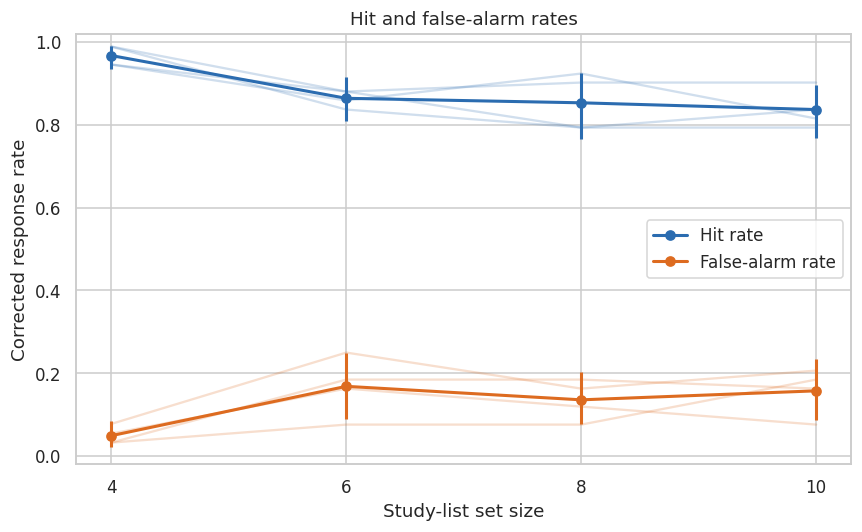

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
for participant, part in metrics.groupby('participant'):
    for metric, color in [('hit_rate', '#2b6cb0'), ('false_alarm_rate', '#dd6b20')]:
        ax.plot(part['set_size'], part[metric], color=color, alpha=0.22)
for metric, label, color in [('hit_rate', 'Hit rate', '#2b6cb0'),
                             ('false_alarm_rate', 'False-alarm rate', '#dd6b20')]:
    ax.plot(group_summary['set_size'], group_summary['mean_' + metric], 'o-',
            color=color, linewidth=2, label=label)
    ax.vlines(group_summary['set_size'], group_summary[metric + '_ci_low'],
              group_summary[metric + '_ci_high'], color=color, linewidth=2)
ax.set(xlabel='Study-list set size', ylabel='Corrected response rate',
       xticks=SET_SIZES, ylim=(-0.02, 1.02), title='Hit and false-alarm rates')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / '01_hit_and_false_alarm_rates.png', bbox_inches='tight')
plt.show()

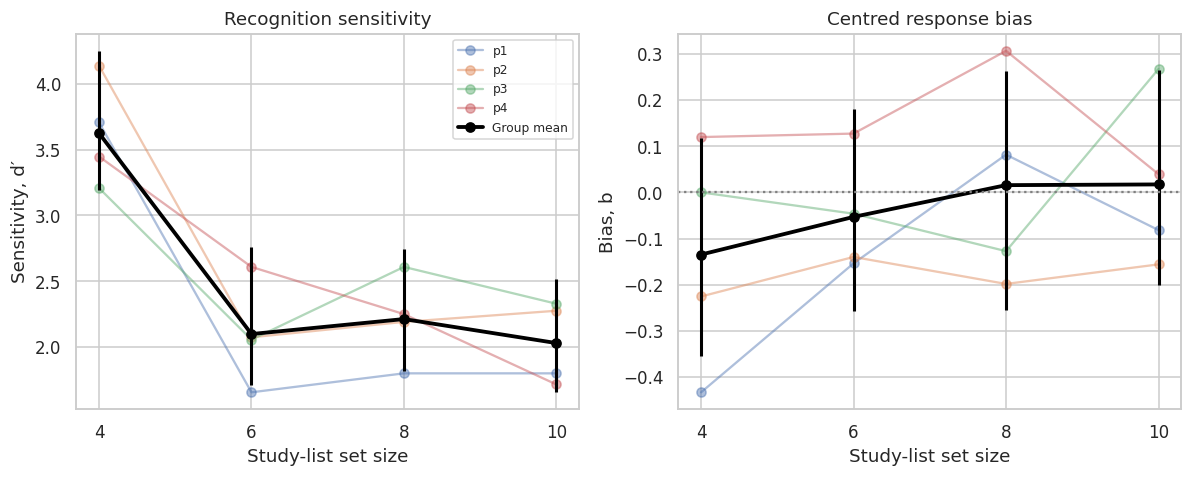

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, title, ylabel in zip(axes, ['dprime', 'bias_b'],
        ['Recognition sensitivity', 'Centred response bias'], ['Sensitivity, d′', 'Bias, b']):
    for participant, part in metrics.groupby('participant'):
        ax.plot(part['set_size'], part[metric], 'o-', alpha=0.45, label=participant)
    ax.plot(group_summary['set_size'], group_summary['mean_' + metric], 'o-',
            color='black', linewidth=2.5, label='Group mean')
    ax.vlines(group_summary['set_size'], group_summary[metric + '_ci_low'],
              group_summary[metric + '_ci_high'], color='black', linewidth=2)
    ax.set(title=title, xlabel='Study-list set size', ylabel=ylabel, xticks=SET_SIZES)
axes[1].axhline(0, color='grey', linestyle=':')
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / '02_dprime_and_bias_vs_set_size.png', bbox_inches='tight')
plt.show()

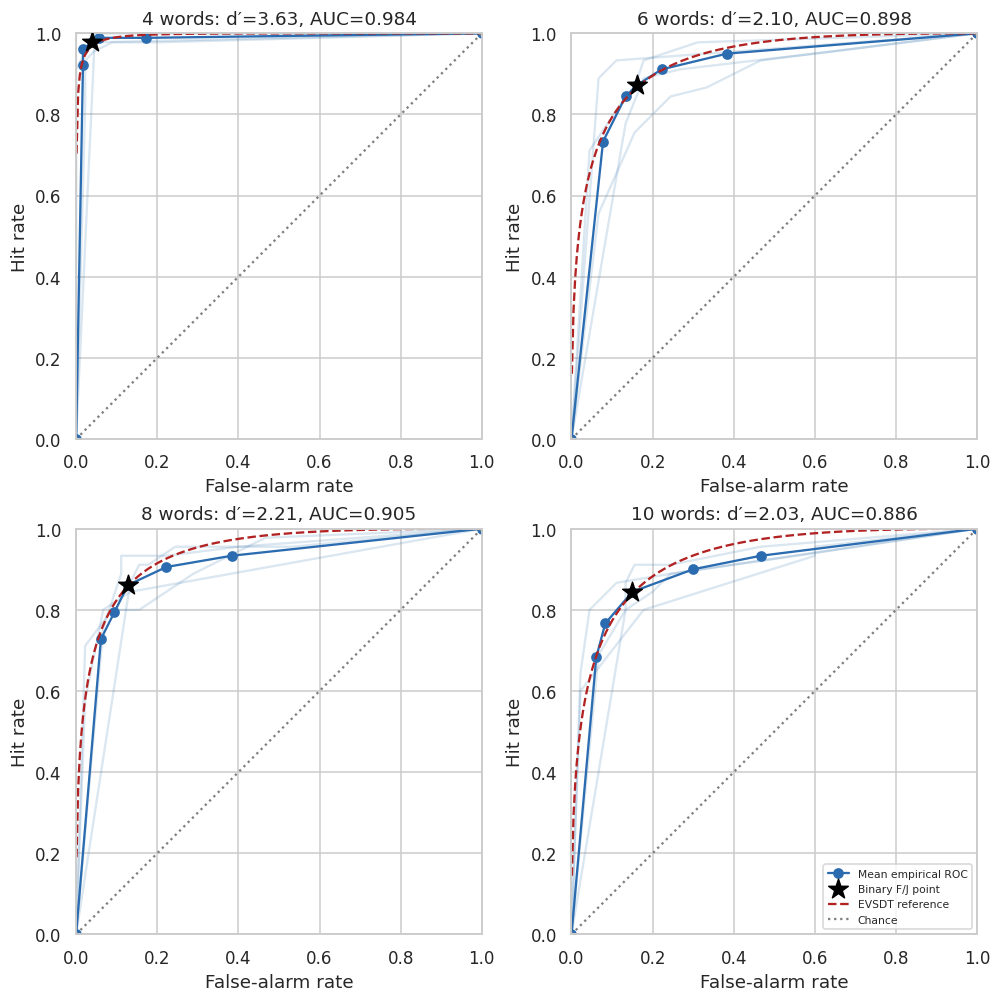

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(9, 9), layout='constrained')
for ax, size in zip(axes.flat, SET_SIZES):
    for participant, part in roc_points.loc[roc_points['set_size'] == size].groupby('participant'):
        part = part.sort_values('threshold', ascending=False)
        ax.plot(part['false_alarm_rate'], part['hit_rate'], color='steelblue', alpha=0.2)
    points = mean_roc.loc[mean_roc['set_size'] == size].sort_values('threshold', ascending=False)
    ax.plot(points['false_alarm_rate'], points['hit_rate'], 'o-', color='#2b6cb0', label='Mean empirical ROC')
    operating = points.loc[points['threshold'] == 4].iloc[0]
    ax.scatter(operating['false_alarm_rate'], operating['hit_rate'], marker='*', s=180,
               color='black', zorder=5, label='Binary F/J point')
    row = group_summary.loc[group_summary['set_size'] == size].iloc[0]
    x = np.linspace(0.001, 0.999, 250)
    ax.plot(x, norm.cdf(norm.ppf(x) + row['mean_dprime']), '--', color='firebrick', label='EVSDT reference')
    ax.plot([0, 1], [0, 1], ':', color='grey', label='Chance')
    ax.set(title=f"{size} words: d′={row['mean_dprime']:.2f}, AUC={row['mean_empirical_auc']:.3f}",
           xlabel='False-alarm rate', ylabel='Hit rate', xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect('equal')
axes[1, 1].legend(loc='lower right', fontsize=7)
fig.savefig(OUTPUT_FOLDER / '03_confidence_roc_by_set_size.png', bbox_inches='tight')
plt.show()

,set_size,Accuracy,n,median_rt,mean_confidence,mean_confidence_rt
0,4,Correct,347,0.822842,2.884726,0.267476
1,4,Incorrect,11,0.963070,1.909091,0.888791
2,6,Correct,308,0.834033,2.737013,0.305043
3,6,Incorrect,52,1.049348,2.211538,0.519908
4,8,Correct,312,0.855754,2.682692,0.334106
5,8,Incorrect,48,1.069799,2.1875,0.524634
6,10,Correct,305,0.828903,2.583607,0.326311
7,10,Incorrect,55,1.082175,2.018182,0.468853


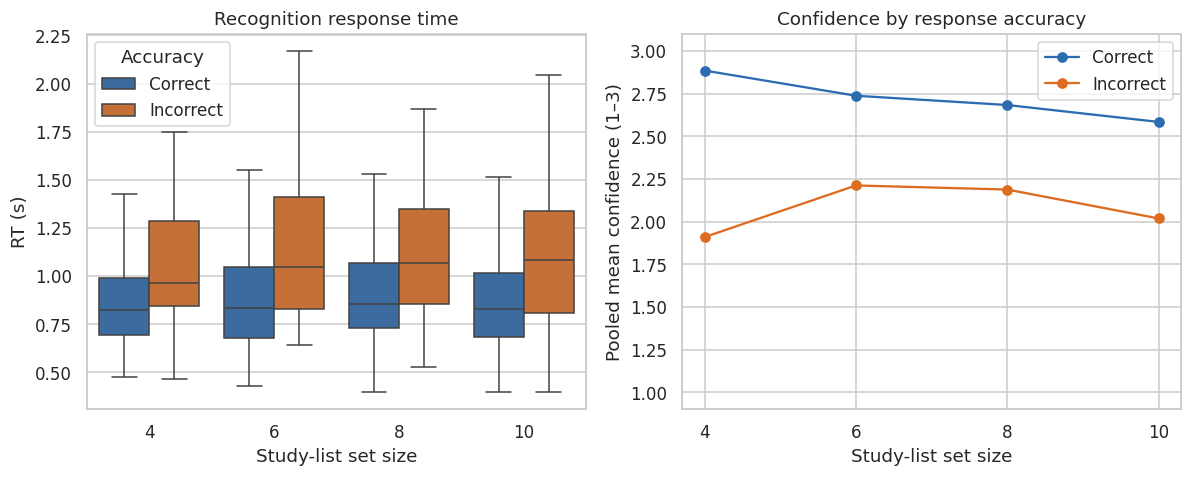

In [15]:
rt_data = valid.copy()
rt_data['Accuracy'] = rt_data['correct'].map({1: 'Correct', 0: 'Incorrect'})
rt_summary = rt_data.groupby(['set_size', 'Accuracy']).agg(
    n=('correct', 'size'), median_rt=('response_rt', 'median'),
    mean_confidence=('confidence', 'mean'), mean_confidence_rt=('confidence_rt', 'mean')).reset_index()
display(rt_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
palette = {'Correct': '#2b6cb0', 'Incorrect': '#dd6b20'}
sns.boxplot(data=rt_data, x='set_size', y='response_rt', hue='Accuracy',
            order=SET_SIZES, hue_order=['Correct', 'Incorrect'],
            palette=palette, showfliers=False, ax=axes[0])
axes[0].set(title='Recognition response time', xlabel='Study-list set size', ylabel='RT (s)')
for accuracy in ['Correct', 'Incorrect']:
    part = rt_summary.loc[rt_summary['Accuracy'] == accuracy]
    axes[1].plot(part['set_size'], part['mean_confidence'], 'o-',
                 color=palette[accuracy], label=accuracy)
axes[1].set(title='Confidence by response accuracy', xlabel='Study-list set size',
            ylabel='Pooled mean confidence (1–3)', xticks=SET_SIZES, ylim=(0.9, 3.1))
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / '04_reaction_time_and_confidence.png', bbox_inches='tight')
plt.show()

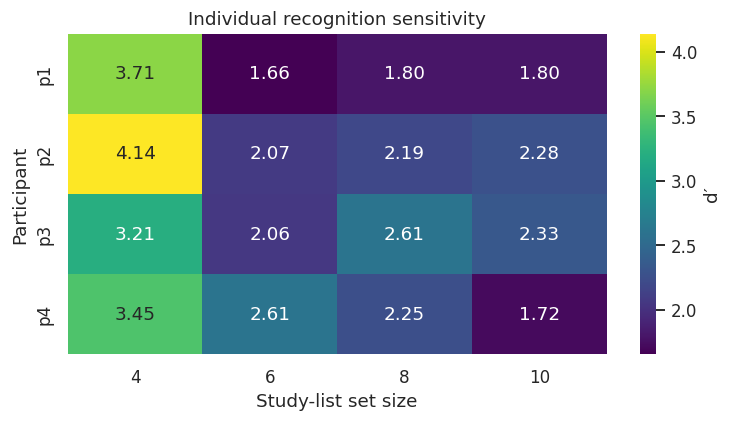

In [16]:
individual = metrics.pivot(index='participant', columns='set_size', values='dprime')
fig, ax = plt.subplots(figsize=(7, 4))
# Automatic colour limits include every observed value; nothing is clipped.
sns.heatmap(individual, annot=True, fmt='.2f', cmap='viridis',
            cbar_kws={'label': 'd′'}, ax=ax)
ax.set(title='Individual recognition sensitivity', xlabel='Study-list set size', ylabel='Participant')
fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / '05_individual_dprime_heatmap.png', bbox_inches='tight')
plt.show()

These reproduce the kinds of tests in the original script. Participants, not probes,
are the independent units. The asymptotic Friedman p-value is unreliable with n=4,
and normality of four slopes cannot be established. Do not treat these p-values as
conclusive population evidence. Section 12 supplies a finite permutation calculation.

In [17]:
test_rows = []
slope_rows = []
for metric in ['dprime', 'bias_b']:
    wide = metrics.pivot(index='participant', columns='set_size', values=metric)
    wide = wide.reindex(columns=SET_SIZES).dropna()
    if len(wide) >= 3:
        statistic, p_value = friedmanchisquare(*[wide[size] for size in SET_SIZES])
        test_rows.append({'test': 'Asymptotic Friedman', 'metric': metric,
                          'statistic': statistic, 'p_value': p_value, 'n': len(wide)})
    slopes = []
    for participant, row in wide.iterrows():
        slope = np.polyfit(SET_SIZES, row.to_numpy(dtype=float), 1)[0]
        slopes.append(slope)
        slope_rows.append({'participant': participant, 'metric': metric, 'slope_per_word': slope})
    if len(slopes) >= 2:
        statistic, p_value = ttest_1samp(slopes, popmean=0)
        test_rows.append({'test': 'Slope t-test (exploratory)', 'metric': metric,
                          'statistic': statistic, 'p_value': p_value, 'n': len(slopes),
                          'mean_slope_per_word': np.mean(slopes)})
original_tests = pd.DataFrame(test_rows)
slopes_table = pd.DataFrame(slope_rows)
display(original_tests)

,test,metric,statistic,p_value,n,mean_slope_per_word
0,Asymptotic Friedman,dprime,8.384615,0.038697,4,NaN
1,Slope t-test (exploratory),dprime,-5.415618,0.012349,4,-0.233554
2,Asymptotic Friedman,bias_b,1.800000,0.614935,4,NaN
3,Slope t-test (exploratory),bias_b,1.726361,0.182739,4,0.026234
